In [38]:
import pandas as pd 
import numpy as np 
import matplotlib.pyplot as plt 

In [39]:
from pathlib import Path

data_dir = Path("data/working")
candidates = sorted(data_dir.glob("*credit*card*clients*.xls*"))
if not candidates:
    raise FileNotFoundError(f"No dataset file found under {data_dir}")

DATA_PATH = str(candidates[0])
df = pd.read_excel(DATA_PATH, header=1)
df.head()

,ID,LIMIT_BAL,SEX,EDUCATION,MARRIAGE,AGE,PAY_0,PAY_2,PAY_3,PAY_4,...,BILL_AMT4,BILL_AMT5,BILL_AMT6,PAY_AMT1,PAY_AMT2,PAY_AMT3,PAY_AMT4,PAY_AMT5,PAY_AMT6,default payment next month
0,1,20000,2,2,1,24,2,2,-1,-1,...,0,0,0,0,689,0,0,0,0,1
1,2,120000,2,2,2,26,-1,2,0,0,...,3272,3455,3261,0,1000,1000,1000,0,2000,1
2,3,90000,2,2,2,34,0,0,0,0,...,14331,14948,15549,1518,1500,1000,1000,1000,5000,0
3,4,50000,2,2,1,37,0,0,0,0,...,28314,28959,29547,2000,2019,1200,1100,1069,1000,0
4,5,50000,1,2,1,57,-1,0,-1,0,...,20940,19146,19131,2000,36681,10000,9000,689,679,0


In [40]:
print(df.shape)

(30000, 25)


In [41]:
df["LIMIT_BAL"].describe()

count      30000.000000
mean      167484.322667
std       129747.661567
min        10000.000000
25%        50000.000000
50%       140000.000000
75%       240000.000000
max      1000000.000000
Name: LIMIT_BAL, dtype: float64

In [42]:
df["LIMIT_BAL"].isna().sum()

np.int64(0)

In [43]:
df["AGE"].describe()

count    30000.000000
mean        35.485500
std          9.217904
min         21.000000
25%         28.000000
50%         34.000000
75%         41.000000
max         79.000000
Name: AGE, dtype: float64

In [44]:
df["AGE"].isna().sum()

np.int64(0)

In [45]:
df["SEX"].value_counts(dropna=False)

SEX
2    18112
1    11888
Name: count, dtype: int64

In [46]:
df["SEX"].isna().sum()

np.int64(0)

In [47]:
df["EDUCATION"].value_counts(dropna = False).sort_index()

EDUCATION
0       14
1    10585
2    14030
3     4917
4      123
5      280
6       51
Name: count, dtype: int64

In [48]:
df["EDUCATION"].isna().sum()

np.int64(0)

In [49]:
df["MARRIAGE"].value_counts(dropna=False).sort_index()

MARRIAGE
0       54
1    13659
2    15964
3      323
Name: count, dtype: int64

In [50]:
df["MARRIAGE"].isna().sum()

np.int64(0)

In [51]:
df["PAY_0"].value_counts(dropna=False).sort_index()

PAY_0
-2     2759
-1     5686
 0    14737
 1     3688
 2     2667
 3      322
 4       76
 5       26
 6       11
 7        9
 8       19
Name: count, dtype: int64

In [52]:
df["PAY_0"].isna().sum()

np.int64(0)

In [53]:
df["PAY_2"].value_counts(dropna=False).sort_index()

PAY_2
-2     3782
-1     6050
 0    15730
 1       28
 2     3927
 3      326
 4       99
 5       25
 6       12
 7       20
 8        1
Name: count, dtype: int64

In [17]:
df["PAY_2"].isna().sum()

np.int64(0)

In [54]:
df["BILL_AMT1"].describe()

count     30000.000000
mean      51223.330900
std       73635.860576
min     -165580.000000
25%        3558.750000
50%       22381.500000
75%       67091.000000
max      964511.000000
Name: BILL_AMT1, dtype: float64

In [55]:
df["BILL_AMT1"].isna().sum()

np.int64(0)

In [56]:
df["PAY_AMT1"].describe()

count     30000.000000
mean       5663.580500
std       16563.280354
min           0.000000
25%        1000.000000
50%        2100.000000
75%        5006.000000
max      873552.000000
Name: PAY_AMT1, dtype: float64

In [57]:
df["PAY_AMT1"].isna().sum()

np.int64(0)

In [58]:
df["default payment next month"].value_counts(dropna=False)

default payment next month
0    23364
1     6636
Name: count, dtype: int64

In [59]:
df["default payment next month"].value_counts(normalize=True)

default payment next month
0    0.7788
1    0.2212
Name: proportion, dtype: float64

In [60]:
df["default payment next month"].isna().sum()

np.int64(0)

## 2. Data Dictionary

| Feature | Type | Meaning | Valid Range / Categories | Missing Allowed? | Possible Risk |
|---|---|---|---|---|---|
| default payment next month | Binary categorical | Whether the client defaults in the following month | 0 = no default, 1 = default | No | Class imbalance |
| LIMIT_BAL | Numeric | Amount of credit granted to the client | Observed: 10,000–1,000,000 | No | Outliers, distribution drift, unexpected missingness |
| AGE | Numeric | Age of the client in years | Observed: 21–79 | No | Impossible values, outliers, demographic/fairness consideration |
| SEX | Categorical | Sex of the client | 1 = male, 2 = female | No | Demographic/fairness consideration, invalid categories |
| EDUCATION | Categorical | Education level of the client | Observed codes: 0–6; codes 0, 5, and 6 require review | No | Unexpected/rare categories, demographic/fairness consideration |
| MARRIAGE | Categorical | Marital status of the client | Observed: 0–3; code 0 requires review | No | Undocumented/rare category, demographic/fairness consideration |
| PAY_0 | Ordinal/coded categorical | Most recent repayment status | Observed: -2 to 8 | No | Rare/unexpected codes, distribution drift |
| PAY_2 | Ordinal/coded categorical | Historical repayment status | Observed: -2 to 8 | No | Rare categories, distribution drift |
| BILL_AMT1 | Numeric | Most recent bill statement amount | Observed: -165,580–964,511 | No | Extreme/negative values requiring interpretation, distribution drift |
| PAY_AMT1 | Numeric | Amount of previous payment | Observed: 0–873,552 | No | Extreme values/outliers, distribution drift |

### Initial Data-Quality Observations

- The `ID` column is an identifier and should not be used as a predictive feature.
- No missing values were observed in the selected features.
- The target variable contains no missing values.
- The target is imbalanced: 77.88% of observations belong to Class 0
  and 22.12% belong to Class 1.
- `EDUCATION` contains rare or undocumented category codes that require
  review before preprocessing.
- `MARRIAGE` contains code 0, which requires review.
- `PAY_0` and `PAY_2` contain rare repayment-status codes.
- `BILL_AMT1` contains negative values that should be interpreted before
  deciding whether they represent valid account balances or data-quality issues.
- Several monetary variables have large differences between their median and
  maximum values, indicating that extreme values should be monitored.
- `SEX`, `EDUCATION`, `MARRIAGE`, and `AGE` are demographic variables and
  should be considered when evaluating fairness and responsible model use.

In [61]:
df.shape

(30000, 25)

In [62]:
df.duplicated().sum()

np.int64(0)

In [63]:
df.duplicated().mean()*100

np.float64(0.0)

In [64]:
df.isna().sum().sum()

np.int64(0)

In [65]:
df.isna().mean().mean() * 100

np.float64(0.0)

In [66]:
duplicate_count = df.duplicated().sum()
duplicate_percentage = df.duplicated().mean() * 100
print("Duplicate rows:", duplicate_count)
print("Duplicate percentage:", duplicate_percentage)

Duplicate rows: 0
Duplicate percentage: 0.0


In [67]:
total_missing = df.isna().sum().sum()
overall_missing_percentage = df.isna().mean().mean() * 100

print("Total missing values:", total_missing)
print("Overall missing percentage:", overall_missing_percentage)

Total missing values: 0
Overall missing percentage: 0.0


In [68]:
numerical_features = [
    "LIMIT_BAL",
    "AGE",
    "BILL_AMT1",
    "PAY_AMT1",
    "BILL_AMT2"  # Fifth numerical feature
]

numerical_profile = df[numerical_features].describe().T

numerical_profile["missing_rate_%"] = (
    df[numerical_features].isna().mean() * 100
)

numerical_profile

,count,mean,std,min,25%,50%,75%,max,missing_rate_%
LIMIT_BAL,30000.0,167484.322667,129747.661567,10000.0,50000.00,140000.0,240000.00,1000000.0,0.0
AGE,30000.0,35.485500,9.217904,21.0,28.00,34.0,41.00,79.0,0.0
BILL_AMT1,30000.0,51223.330900,73635.860576,-165580.0,3558.75,22381.5,67091.00,964511.0,0.0
PAY_AMT1,30000.0,5663.580500,16563.280354,0.0,1000.00,2100.0,5006.00,873552.0,0.0
BILL_AMT2,30000.0,49179.075167,71173.768783,-69777.0,2984.75,21200.0,64006.25,983931.0,0.0


### Numerical Profiling Observations

Five numerical features were profiled: `LIMIT_BAL`, `AGE`, `BILL_AMT1`, `PAY_AMT1`, and `BILL_AMT2`.

All five features contained 30,000 non-missing observations. The monetary variables showed evidence of right-skewed distributions and potentially extreme values. Negative bill amounts were observed and require further interpretation before being classified as data-quality errors.

Median imputation was selected as an initial candidate for the missing-data recovery experiment because it is relatively robust to extreme values.

`LIMIT_BAL` was selected as the preliminary numerical distribution-drift monitoring candidate because it is interpretable and exhibits meaningful variation across clients.

These findings describe the complete dataset during exploratory profiling. The final operational reference profile will be calculated using training data only.

In [70]:
categorical_features = [
    "SEX",
    "EDUCATION",
    "MARRIAGE",
    "PAY_0",
    "PAY_2"
]

for feature in categorical_features:
    print(f"\nFeature: {feature}")

    print("Unique categories:",
          df[feature].nunique(dropna=True))

    print("Category proportions (%):")
    print(
        (df[feature].value_counts(
            normalize=True,
            dropna=False
        ) * 100).round(2)
    )

    print("Missing rate (%):",
          df[feature].isna().mean() * 100)


Feature: SEX
Unique categories: 2
Category proportions (%):
SEX
2    60.37
1    39.63
Name: proportion, dtype: float64
Missing rate (%): 0.0

Feature: EDUCATION
Unique categories: 7
Category proportions (%):
EDUCATION
2    46.77
1    35.28
3    16.39
5     0.93
4     0.41
6     0.17
0     0.05
Name: proportion, dtype: float64
Missing rate (%): 0.0

Feature: MARRIAGE
Unique categories: 4
Category proportions (%):
MARRIAGE
2    53.21
1    45.53
3     1.08
0     0.18
Name: proportion, dtype: float64
Missing rate (%): 0.0

Feature: PAY_0
Unique categories: 11
Category proportions (%):
PAY_0
 0    49.12
-1    18.95
 1    12.29
-2     9.20
 2     8.89
 3     1.07
 4     0.25
 5     0.09
 8     0.06
 6     0.04
 7     0.03
Name: proportion, dtype: float64
Missing rate (%): 0.0

Feature: PAY_2
Unique categories: 11
Category proportions (%):
PAY_2
 0    52.43
-1    20.17
 2    13.09
-2    12.61
 3     1.09
 4     0.33
 1     0.09
 5     0.08
 7     0.07
 6     0.04
 8     0.00
Name: proportion

In [71]:
rare_threshold = 0.01  # 1%

categorical_features = [
    "SEX",
    "EDUCATION",
    "MARRIAGE",
    "PAY_0",
    "PAY_2"
]

for feature in categorical_features:

    proportions = df[feature].value_counts(
        normalize=True,
        dropna=False
    )

    rare_categories = proportions[
        proportions < rare_threshold
    ]

    print(f"\nFeature: {feature}")
    print("Rare categories (<1%):")

    if rare_categories.empty:
        print("No rare categories found.")
    else:
        print((rare_categories * 100).round(3))


Feature: SEX
Rare categories (<1%):
No rare categories found.

Feature: EDUCATION
Rare categories (<1%):
EDUCATION
5    0.933
4    0.410
6    0.170
0    0.047
Name: proportion, dtype: float64

Feature: MARRIAGE
Rare categories (<1%):
MARRIAGE
0    0.18
Name: proportion, dtype: float64

Feature: PAY_0
Rare categories (<1%):
PAY_0
4    0.253
5    0.087
8    0.063
6    0.037
7    0.030
Name: proportion, dtype: float64

Feature: PAY_2
Rare categories (<1%):
PAY_2
4    0.330
1    0.093
5    0.083
7    0.067
6    0.040
8    0.003
Name: proportion, dtype: float64


### 3.4 Rare-Category Analysis

**Preliminary rare-category threshold:** Less than 1% of observations.

Five categorical and ordinal features were examined for rare categories.

- `SEX`: No rare categories identified.
- `EDUCATION`: Codes 0, 4, 5, and 6 were rare.
- `MARRIAGE`: Code 0 was rare.
- `PAY_0`: Codes 4, 5, 6, 7, and 8 were rare.
- `PAY_2`: Codes 1, 4, 5, 6, 7, and 8 were rare.

Rare categories will be retained during initial profiling. Undocumented category codes will be investigated before preprocessing.

The 1% threshold is preliminary and will be evaluated using the training reference population.

No rare categories have been removed, combined, or modified.

In [72]:
from sklearn.model_selection import train_test_split

target = "default payment next month"

X = df.drop(columns=["ID", target])
y = df[target]

# First split: 70% training, 30% temporary
X_train, X_temp, y_train, y_temp = train_test_split(
    X,
    y,
    test_size=0.30,
    random_state=42,
    stratify=y
)

# Second split: 15% validation, 15% test
X_val, X_test, y_val, y_test = train_test_split(
    X_temp,
    y_temp,
    test_size=0.50,
    random_state=42,
    stratify=y_temp
)

print("Training:", X_train.shape)
print("Validation:", X_val.shape)
print("Test:", X_test.shape)

print("\nClass 1 proportions:")
print("Training:", round(y_train.mean() * 100, 2), "%")
print("Validation:", round(y_val.mean() * 100, 2), "%")
print("Test:", round(y_test.mean() * 100, 2), "%")

Training: (21000, 23)
Validation: (4500, 23)
Test: (4500, 23)

Class 1 proportions:
Training: 22.12 %
Validation: 22.11 %
Test: 22.13 %


In [73]:
%pip install ipywidgets matplotlib

Note: you may need to restart the kernel to use updated packages.


In [74]:
import matplotlib.pyplot as plt
import ipywidgets as widgets
from IPython.display import display

# Preliminary detector settings
reference_missing_rate = 0.0
threshold_increase = 5.0
batch_size = 1000

def visualize_missingness(missing_rate=15):
    missing_count = round(batch_size * missing_rate / 100)
    missingness_increase = missing_rate - reference_missing_rate

    failure_detected = missingness_increase > threshold_increase

    fig, ax = plt.subplots(figsize=(8, 4))

    ax.bar(
        ["Reference", "Current Batch"],
        [reference_missing_rate, missing_rate],
        color=["steelblue", "tomato" if failure_detected else "seagreen"]
    )

    ax.axhline(
        reference_missing_rate + threshold_increase,
        color="darkorange",
        linestyle="--",
        label="Detection threshold (5%)"
    )

    ax.set_ylim(0, 35)
    ax.set_ylabel("Missingness Rate (%)")
    ax.set_title("SHML Trial 1: BILL_AMT1 Missingness Detector")
    ax.legend()

    plt.show()

    print(f"Missing BILL_AMT1 values: {missing_count} / {batch_size}")
    print(f"Current missingness: {missing_rate}%")

    if failure_detected:
        print("FAILURE DETECTED — Healing evaluation required")
    else:
        print("NO FAILURE — Within preliminary threshold")

widgets.interact(
    visualize_missingness,
    missing_rate=widgets.IntSlider(
        value=15,
        min=0,
        max=30,
        step=1,
        description="Missing %:"
    )
)

interactive(children=(IntSlider(value=15, description='Missing %:', max=30), Output()), _dom_classes=('widget-…

<function __main__.visualize_missingness(missing_rate=15)>

### 3.5 Missingness Monitoring Candidate

**Selected feature:** `BILL_AMT1`

**Reason for selection:** `BILL_AMT1` is a numeric feature representing the most recent bill statement amount. The initial dataset contains 0% missing values. Its mean (51,223.33) is considerably higher than its median (22,381.50), suggesting a skewed distribution.

**Potential failure:** An increase in missing bill statement amounts in incoming data.

**Monitoring statistic:** Percentage of missing values in `BILL_AMT1`.

**Preliminary detection threshold:** Flag missingness when the rate exceeds the healthy training reference by more than five percentage points.

**Proposed correction:** Median imputation using the median calculated from healthy training data.

**Validation:** Evaluate the corrected pipeline against predefined recovery metrics and acceptance thresholds.

**Safety:** Reject an unsuccessful correction and retain the previously approved pipeline.

**Current status:** Monitoring and healing are planned but not yet implemented. Final reference statistics will be calculated from the training split.

## 1. Train / Validation / Test Split

In [75]:
from sklearn.model_selection import train_test_split

target = "default payment next month"

X = df.drop(columns=["ID", target])
y = df[target]

X_train, X_temp, y_train, y_temp = train_test_split(
    X, y,
    test_size=0.30,
    random_state=42,
    stratify=y
)

X_val, X_test, y_val, y_test = train_test_split(
    X_temp, y_temp,
    test_size=0.50,
    random_state=42,
    stratify=y_temp
)

print("Training:", X_train.shape)
print("Validation:", X_val.shape)
print("Test:", X_test.shape)

print("\nDefault rate:")
print("Training:", round(y_train.mean() * 100, 2), "%")
print("Validation:", round(y_val.mean() * 100, 2), "%")
print("Test:", round(y_test.mean() * 100, 2), "%")

Training: (21000, 23)
Validation: (4500, 23)
Test: (4500, 23)

Default rate:
Training: 22.12 %
Validation: 22.11 %
Test: 22.13 %


## 2. Healthy Reference Profile — BILL_AMT1

In [76]:
# Healthy reference statistics from training data only

bill_reference = X_train["BILL_AMT1"]

healthy_reference = {
    "feature": "BILL_AMT1",
    "count": bill_reference.count(),
    "missing_rate_%": bill_reference.isna().mean() * 100,
    "mean": bill_reference.mean(),
    "median": bill_reference.median(),
    "std": bill_reference.std(),
    "min": bill_reference.min(),
    "max": bill_reference.max()
}

for key, value in healthy_reference.items():
    print(f"{key}: {value}")

feature: BILL_AMT1
count: 21000
missing_rate_%: 0.0
mean: 51194.21880952381
median: 22225.5
std: 73633.9823063457
min: -165580
max: 964511


## 3. Interactive Missingness Detector Visualization

In [ ]:
import matplotlib.pyplot as plt
import ipywidgets as widgets
from IPython.display import display, clear_output

reference_rate = healthy_reference["missing_rate_%"]
threshold_increase = 5.0
batch_size = 1000

slider = widgets.IntSlider(
    value=15,
    min=0,
    max=30,
    step=1,
    description="Missing %:",
    continuous_update=False
)

output = widgets.Output()

def update_chart(change=None):
    missing_rate = slider.value
    missing_count = int(batch_size * missing_rate / 100)

    detection_limit = reference_rate + threshold_increase
    failure = missing_rate > detection_limit

    with output:
        clear_output(wait=True)

        fig, ax = plt.subplots(figsize=(7, 4))

        ax.bar(
            ["Healthy Reference", "Simulated Batch"],
            [reference_rate, missing_rate],
            color=["steelblue", "tomato" if failure else "seagreen"]
        )

        ax.axhline(
            detection_limit,
            color="darkorange",
            linestyle="--",
            label=f"Threshold ({detection_limit:.1f}%)"
        )

        ax.set_ylim(0, 35)
        ax.set_ylabel("Missingness Rate (%)")
        ax.set_title("SHML Trial 1 — BILL_AMT1 Missingness")
        ax.legend()

        plt.show()
        plt.close(fig)

        print(f"Missing values: {missing_count}/{batch_size}")
        print(f"Current missingness: {missing_rate}%")

        if failure:
            print("FAILURE DETECTED — Healing evaluation required")
        else:
            print("NO FAILURE — Within threshold")

slider.observe(update_chart, names="value")
display(slider, output)
update_chart()

IntSlider(value=15, continuous_update=False, description='Missing %:', max=30)

Output()

## Training Dataset — Healthy Reference Summary

In [78]:
# Training dataset reference characteristics

train_df = X_train.copy()
train_df["default payment next month"] = y_train

print("Training rows:", len(train_df))
print("Features before exclusions (full dataset):", df.shape[1])
print("Features after exclusions:", X_train.shape[1])

print("Duplicate rows:", train_df.duplicated().sum())

print(
    "Duplicate percentage:",
    round(train_df.duplicated().mean() * 100, 2)
)

print("Missing feature cells:", X_train.isna().sum().sum())

print(
    "Missing feature percentage:",
    round(X_train.isna().mean().mean() * 100, 2)
)

print("Positive class percentage:", round(y_train.mean() * 100, 2))
print("Negative class percentage:", round((1 - y_train.mean()) * 100, 2))

Training rows: 21000
Features before exclusions (full dataset): 25
Features after exclusions: 23
Duplicate rows: 18
Duplicate percentage: 0.09
Missing feature cells: 0
Missing feature percentage: 0.0
Positive class percentage: 22.12
Negative class percentage: 77.88


In [79]:
# Investigate duplicate records without modifying data

duplicate_mask = train_df.duplicated(keep=False)

print("Rows belonging to duplicate groups:",
      duplicate_mask.sum())

print("Duplicate rows beyond first occurrence:",
      train_df.duplicated().sum())

display(
    train_df.loc[duplicate_mask]
    .sort_values(by="LIMIT_BAL")
    .head(10)
)

Rows belonging to duplicate groups: 36
Duplicate rows beyond first occurrence: 18


,LIMIT_BAL,SEX,EDUCATION,MARRIAGE,AGE,PAY_0,PAY_2,PAY_3,PAY_4,PAY_5,...,BILL_AMT4,BILL_AMT5,BILL_AMT6,PAY_AMT1,PAY_AMT2,PAY_AMT3,PAY_AMT4,PAY_AMT5,PAY_AMT6,default payment next month
12430,20000,1,2,2,24,2,2,4,4,4,...,1650,1650,1650,0,0,0,0,0,0,1
14294,20000,1,2,2,24,2,2,4,4,4,...,1650,1650,1650,0,0,0,0,0,0,1
7170,50000,2,1,2,23,1,-2,-2,-2,-2,...,0,0,0,0,0,0,0,0,0,0
17032,50000,2,1,2,23,1,-2,-2,-2,-2,...,0,0,0,0,0,0,0,0,0,0
28983,80000,2,3,1,42,-2,-2,-2,-2,-2,...,0,0,0,0,0,0,0,0,0,0
6785,80000,2,3,1,42,-2,-2,-2,-2,-2,...,0,0,0,0,0,0,0,0,0,0
7366,80000,2,2,1,31,-2,-2,-2,-2,-2,...,0,0,0,0,0,0,0,0,0,0
19114,80000,2,2,1,31,-2,-2,-2,-2,-2,...,0,0,0,0,0,0,0,0,0,0
13912,140000,1,1,2,29,1,-2,-2,-2,-2,...,0,0,0,0,0,0,0,0,0,0
24122,140000,1,1,2,29,1,-2,-2,-2,-2,...,0,0,0,0,0,0,0,0,0,0


**Duplicate Record Investigation**

The training dataset contains 21,000 observations. After excluding the identifier column, 36 records belong to duplicate groups, corresponding to 18 duplicate occurrences beyond the first (approximately 0.086%).

These records may represent different customers with identical feature values and target labels. Because their validity has not been disproven, they will be retained during initial profiling.

No duplicate records have been removed.

In [80]:
# Target distribution in training data

target_counts = y_train.value_counts().sort_index()
target_percentages = (
    y_train.value_counts(normalize=True).sort_index() * 100
)

print("Target counts:")
print(target_counts)

print("\nTarget percentages:")
print(target_percentages.round(2))

print("\nMissing target values:", y_train.isna().sum())

print(
    "Unexpected target values:",
    set(y_train.dropna().unique()) - {0, 1}
)

# Accuracy of a model that always predicts the majority class
naive_accuracy = y_train.value_counts(normalize=True).max() * 100

print(f"\nMajority-class naive accuracy: {naive_accuracy:.2f}%")

Target counts:
default payment next month
0    16355
1     4645
Name: count, dtype: int64

Target percentages:
default payment next month
0    77.88
1    22.12
Name: proportion, dtype: float64

Missing target values: 0
Unexpected target values: set()

Majority-class naive accuracy: 77.88%


## 4. Training Numerical Feature Profile

In [81]:
numerical_features = [
    "LIMIT_BAL",
    "AGE",
    "BILL_AMT1",
    "PAY_AMT1",
    "BILL_AMT2"
]

# Training data only
numerical_profile_train = X_train[numerical_features].describe().T

numerical_profile_train["missing_rate_%"] = (
    X_train[numerical_features].isna().mean() * 100
)

display(numerical_profile_train)

,count,mean,std,min,25%,50%,75%,max,missing_rate_%
LIMIT_BAL,21000.0,167499.142857,129767.049797,10000.0,50000.00,140000.0,240000.00,1000000.0,0.0
AGE,21000.0,35.428048,9.184785,21.0,28.00,34.0,41.00,75.0,0.0
BILL_AMT1,21000.0,51194.218810,73633.982306,-165580.0,3509.75,22225.5,67062.75,964511.0,0.0
PAY_AMT1,21000.0,5654.306714,16424.968267,0.0,1000.00,2118.5,5021.25,873552.0,0.0
BILL_AMT2,21000.0,49140.803905,71162.698748,-69777.0,2999.50,20993.0,64137.25,983931.0,0.0


### 4.1 Mean vs. Median — Training Numerical Features

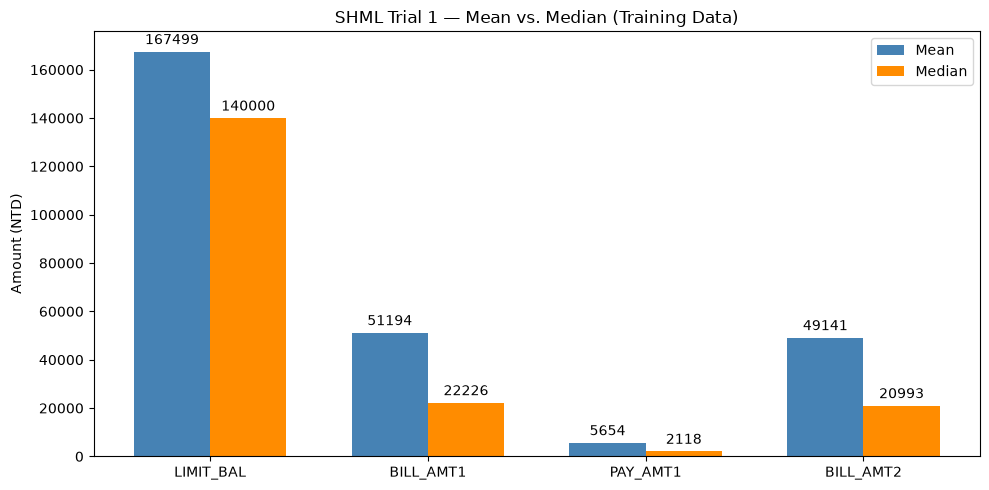

In [83]:
import matplotlib.pyplot as plt
import numpy as np

features = [
    "LIMIT_BAL",
    "BILL_AMT1",
    "PAY_AMT1",
    "BILL_AMT2"
]

means = X_train[features].mean()
medians = X_train[features].median()

x = np.arange(len(features))
width = 0.35

fig, ax = plt.subplots(figsize=(10, 5))

bars_mean = ax.bar(
    x - width / 2,
    means,
    width,
    label="Mean",
    color="steelblue"
)

bars_median = ax.bar(
    x + width / 2,
    medians,
    width,
    label="Median",
    color="darkorange"
)

ax.set_xticks(x)
ax.set_xticklabels(features)
ax.set_ylabel("Amount (NTD)")
ax.set_title("SHML Trial 1 — Mean vs. Median (Training Data)")
ax.legend()

ax.bar_label(bars_mean, fmt="%.0f", padding=3)
ax.bar_label(bars_median, fmt="%.0f", padding=3)

plt.tight_layout()
plt.show()
plt.close(fig)

The mean values of the selected monetary features are higher than their corresponding medians, suggesting positively skewed distributions. This observation supports investigating median imputation for missing-value recovery because the median is less sensitive to extreme observations than the mean. The final choice of imputation strategy will be evaluated experimentally.

## 5. Training Categorical Feature Profile

In [82]:
categorical_features = [
    "SEX",
    "EDUCATION",
    "MARRIAGE",
    "PAY_0",
    "PAY_2"
]

rare_threshold = 0.01

for feature in categorical_features:
    counts = X_train[feature].value_counts(dropna=False)
    proportions = X_train[feature].value_counts(
        normalize=True,
        dropna=False
    )

    rare_categories = proportions[proportions < rare_threshold]

    print(f"\nFeature: {feature}")
    print("Missing rate (%):", round(X_train[feature].isna().mean() * 100, 2))
    print("Unique values:", X_train[feature].nunique(dropna=False))
    print("Most common category:", counts.idxmax())
    print("Top category (%):", round(proportions.max() * 100, 2))
    print("Rare categories (<1%):", rare_categories.index.tolist())


Feature: SEX
Missing rate (%): 0.0
Unique values: 2
Most common category: 2
Top category (%): 60.36
Rare categories (<1%): []

Feature: EDUCATION
Missing rate (%): 0.0
Unique values: 7
Most common category: 2
Top category (%): 46.82
Rare categories (<1%): [4, 6, 0]

Feature: MARRIAGE
Missing rate (%): 0.0
Unique values: 4
Most common category: 2
Top category (%): 53.37
Rare categories (<1%): [0]

Feature: PAY_0
Missing rate (%): 0.0
Unique values: 11
Most common category: 0
Top category (%): 48.98
Rare categories (<1%): [4, 5, 8, 6, 7]

Feature: PAY_2
Missing rate (%): 0.0
Unique values: 11
Most common category: 0
Top category (%): 52.31
Rare categories (<1%): [4, 1, 5, 7, 6, 8]


### Training Categorical Feature Profile

Five categorical or ordinal features were examined using the 21,000 training observations: `SEX`, `EDUCATION`, `MARRIAGE`, `PAY_0`, and `PAY_2`.

All five features have 0% missingness.

A preliminary rare-category threshold of less than 1% was applied.

- **SEX:** 2 unique categories; no rare categories.
- **EDUCATION:** 7 unique categories; rare codes 0, 4, and 6.
- **MARRIAGE:** 4 unique categories; rare code 0.
- **PAY_0:** 11 unique categories; rare codes 4, 5, 6, 7, and 8.
- **PAY_2:** 11 unique categories; rare codes 1, 4, 5, 6, 7, and 8.

The most common categories were SEX = 2 (60.36%), EDUCATION = 2 (46.82%), MARRIAGE = 2 (53.37%), PAY_0 = 0 (48.98%), and PAY_2 = 0 (52.31%).

The rare-category findings differ slightly from the full-dataset profile, reinforcing the importance of establishing the operational reference using training observations only.

Rare categories will be retained during initial profiling. Undocumented codes will be investigated before any preprocessing decisions are made.

### 5.1 PAY_0 Category Distribution — Training Data

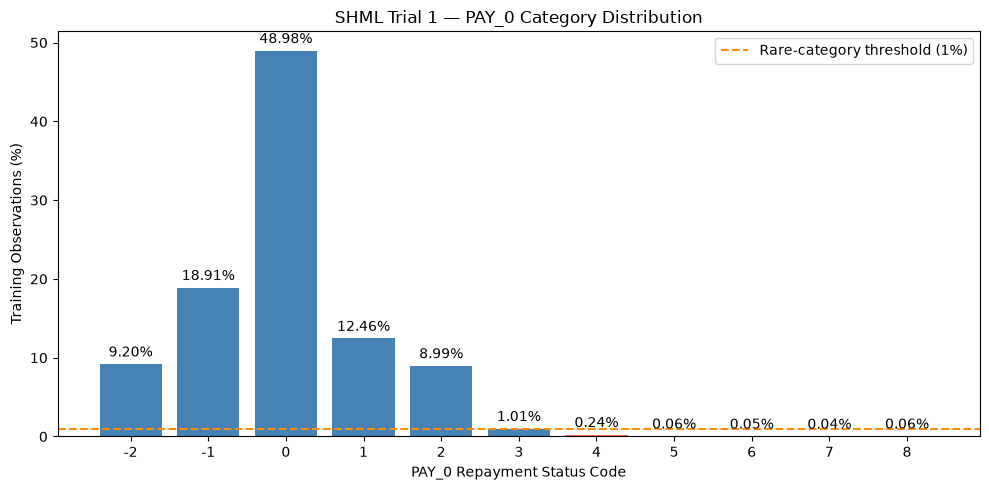

In [84]:
import matplotlib.pyplot as plt

pay0_percentages = (
    X_train["PAY_0"]
    .value_counts(normalize=True)
    .sort_index() * 100
)

fig, ax = plt.subplots(figsize=(10, 5))

colors = [
    "tomato" if percentage < 1 else "steelblue"
    for percentage in pay0_percentages
]

bars = ax.bar(
    pay0_percentages.index.astype(str),
    pay0_percentages.values,
    color=colors
)

ax.axhline(
    1,
    color="darkorange",
    linestyle="--",
    label="Rare-category threshold (1%)"
)

ax.set_xlabel("PAY_0 Repayment Status Code")
ax.set_ylabel("Training Observations (%)")
ax.set_title("SHML Trial 1 — PAY_0 Category Distribution")
ax.legend()

ax.bar_label(bars, fmt="%.2f%%", padding=3)

plt.tight_layout()
plt.show()
plt.close(fig)

### 5.2 Investigating Unusual Categorical Values

In [85]:
# Inspect potentially undocumented category codes
unusual_codes = {
    "EDUCATION": [0, 5, 6],
    "MARRIAGE": [0]
}

for feature, codes in unusual_codes.items():
    print(f"\nFeature: {feature}")

    counts = X_train[feature].value_counts().sort_index()

    for code in codes:
        count = counts.get(code, 0)
        percentage = count / len(X_train) * 100

        print(
            f"Code {code}: {count} observations "
            f"({percentage:.3f}%)"
        )


Feature: EDUCATION
Code 0: 12 observations (0.057%)
Code 5: 211 observations (1.005%)
Code 6: 37 observations (0.176%)

Feature: MARRIAGE
Code 0: 40 observations (0.190%)


### Investigation of Unusual Categorical Values

The training dataset was examined for potentially undocumented categorical codes.

For `EDUCATION`, codes 0, 5, and 6 occurred in 12 (0.057%), 211 (1.005%), and 37 (0.176%) observations, respectively.

For `MARRIAGE`, code 0 occurred in 40 observations (0.190%).

These codes are not included in the primary documented category definitions and require interpretation.

The investigation also demonstrated that rare-category status and data validity are separate concepts. For example, `EDUCATION = 5` exceeds the 1% rare-category threshold but still requires documentation review.

No categories were removed, replaced, or combined during profiling. Future monitoring will distinguish known uncommon values from previously unseen values.

## SHML Trial 1 — Healthy Reference Profile Observations

### Observation 1: Data-Quality Risk
The most important data-quality risk for Trial 1 is missing financial information because BILL_AMT1 has a healthy training missingness rate of 0%, and missing values could reduce the reliability of credit-default predictions.

### Observation 2: Failure Simulation
The first failure I will simulate is increased missingness in BILL_AMT1 because the feature has a right-skewed distribution (mean = 51,194.22; median = 22,225.50), making it a useful candidate for evaluating median-imputation recovery.

### Observation 3: Numerical Drift
I will use LIMIT_BAL as the initial numerical-drift candidate because it has substantial variation (median = 140,000; standard deviation = 129,767.05). Changes in its distribution could indicate shifts in the incoming customer population.

### Research Decision
The healthy reference profile was established using the 21,000 training observations. No actual failure injection, automated correction, or recovery evaluation was performed during this profiling assignment.

### 5.3 Investigation of Negative Bill Amounts

In [86]:
# Investigate negative bill amounts using training data only

bill_features = ["BILL_AMT1", "BILL_AMT2"]

for feature in bill_features:
    negative_values = X_train[feature] < 0

    count = negative_values.sum()
    percentage = negative_values.mean() * 100

    print(f"\nFeature: {feature}")
    print(f"Negative observations: {count}")
    print(f"Negative percentage: {percentage:.3f}%")
    print(f"Minimum value: {X_train[feature].min()}")

# Inspect a few examples without changing the dataset
display(
    X_train.loc[
        X_train["BILL_AMT1"] < 0,
        ["LIMIT_BAL", "BILL_AMT1", "BILL_AMT2", "PAY_AMT1"]
    ].head(10)
)


Feature: BILL_AMT1
Negative observations: 412
Negative percentage: 1.962%
Minimum value: -165580

Feature: BILL_AMT2
Negative observations: 457
Negative percentage: 2.176%
Minimum value: -69777


,LIMIT_BAL,BILL_AMT1,BILL_AMT2,PAY_AMT1
27959,170000,-807,-807,0
25466,360000,-307,-307,0
8535,250000,-24,-24,0
22998,150000,-260,-2835,4
24113,280000,-650,-650,0
27203,280000,-191,-191,0
24921,170000,-21,-21,0
25449,50000,-1037,-1037,0
24360,100000,-342,-342,0
17865,50000,-727,50268,53860


### Investigation of Negative Bill Amounts

Negative bill statement amounts were identified in the training dataset.

| Feature | Negative observations | Percentage | Minimum |
|---|---:|---:|---:|
| BILL_AMT1 | 412 | 1.962% | -165,580 |
| BILL_AMT2 | 457 | 2.176% | -69,777 |

Negative bill amounts may reflect account credits, overpayments, or financial adjustments. However, their exact meaning cannot be confirmed from the available dataset documentation.

**Preprocessing decision:** Retain negative bill amounts in the initial training dataset. Do not replace them with zero or treat them as missing values.

**Monitoring implication:** Negative values observed in the healthy reference should not automatically trigger a data-quality failure.

**Limitation:** The financial interpretation of these negative balances remains unverified and is documented as a data-semantics limitation.

## Phase 2 Conclusion — Healthy Reference Profile

A healthy reference profile was established using 21,000 training observations and 23 predictor features from the UCI Default of Credit Card Clients dataset.

The training data contained no missing feature values. The positive class represented approximately 22.12% of observations, highlighting the importance of recall and F1-score alongside accuracy.

Numerical and categorical feature distributions were examined, including rare categories, undocumented codes, and negative bill amounts. These unusual values were retained because there was insufficient evidence to classify them as data errors.

Five monitoring candidates were selected: schema validation, missingness, numerical drift, categorical shift, and class balance. BILL_AMT1 was selected for the first missingness experiment, LIMIT_BAL for numerical drift, and PAY_0 for categorical shift.

The resulting profile provides a reference for future SHML failure-detection experiments. No automated failure injection, correction, or recovery evaluation was performed in this phase.